# 08_04 — Best virtual diagnostic: measured vs inferred BCM

Results of the best model: **improved two-stage model of `08_05`** (stage 1 trained on the most recent shots,
stage 2 = MLP trained on the concordance loss, 6 seeds), on the test shots of every segment (after the cut, BCM
assumed lost; shots with beam). Predictions are read from `results/virtual_diagnostic/predictions_08_05.csv`
(run `08_05` first). To see the earlier model of `08_03` instead, set `PRED_FILE = "predictions_08_03.csv"` and
`MODEL = "MLP · CCC"`.

For every segment:
1. **time series** — measured and inferred charge overlapped, over the whole test period and zoomed on 150 shots
2. **difference** — inferred − measured, shot by shot
3. **distributions** — of the charge values, of the shot-to-shot fluctuation (value − 51-shot rolling mean), and of the difference

At the end, a summary over all segments.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts"))
import vd_plots   # summary table and plots, shared with 08_05

OUT = REPO / "results" / "virtual_diagnostic"
FIGS = OUT / "best_model"
FIGS.mkdir(parents=True, exist_ok=True)

PRED_FILE = "predictions_08_05.csv"
MODEL = "improved (08_05)"

pred = pd.read_csv(OUT / PRED_FILE)
segments = sorted(pred["segment"].unique())
print(f"{len(pred)} test shots in {len(segments)} segments, model: {MODEL}")

17217 test shots in 7 segments, model: improved (08_05)


## Summary table

Difference = inferred − measured, in **pC**; relative values are divided by the mean measured charge of the segment.

In [2]:
summary = vd_plots.summary_table(pred, MODEL)
summary.style.format(vd_plots.TABLE_FORMAT)

,shots,mean measured [nC],mean inferred [nC],bias [pC],std diff [pC],95% of |diff| below [pC],max |diff| [pC],std diff / mean,corr (shot by shot),corr of fluctuations,fluctuation size (inferred / measured)
segment,,,,,,,,,,,
0,1411,0.249,0.243,-5.8,12.9,27.6,64.5,5.2%,0.83,0.84,0.85
1,5645,4.821,4.754,-66.9,120.6,279.6,920.3,2.5%,0.94,0.76,0.92
3,1664,0.124,0.123,-1.6,12.7,26.6,104.8,10.2%,0.67,0.63,0.84
4,1166,0.102,0.102,-0.3,12.9,26.0,62.6,12.6%,0.81,0.66,1.05
5,5863,5.550,5.561,+10.6,127.4,285.7,949.0,2.3%,0.95,0.73,0.88
6,933,5.444,5.445,+0.9,48.6,93.5,177.9,0.9%,0.99,0.98,1.01
7,535,10.122,10.065,-57.0,229.6,472.8,1663.7,2.3%,0.94,0.94,0.88


## One figure per segment

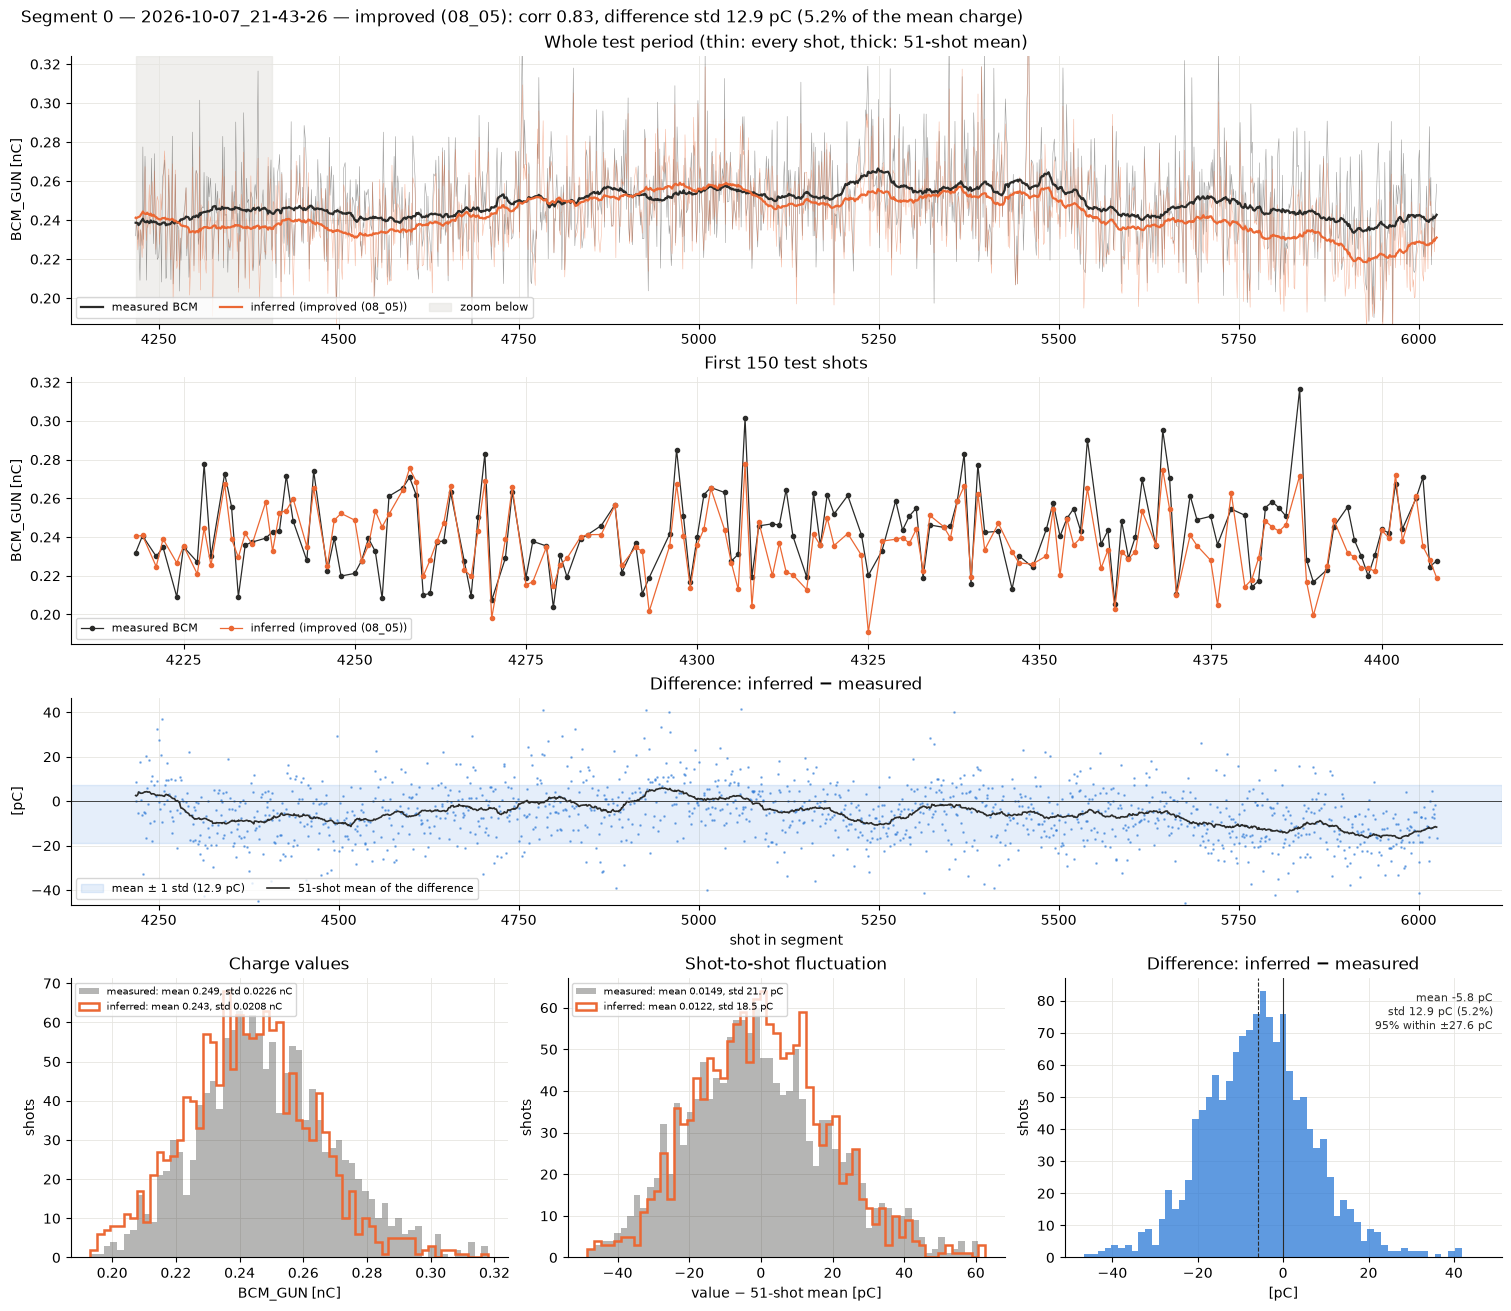

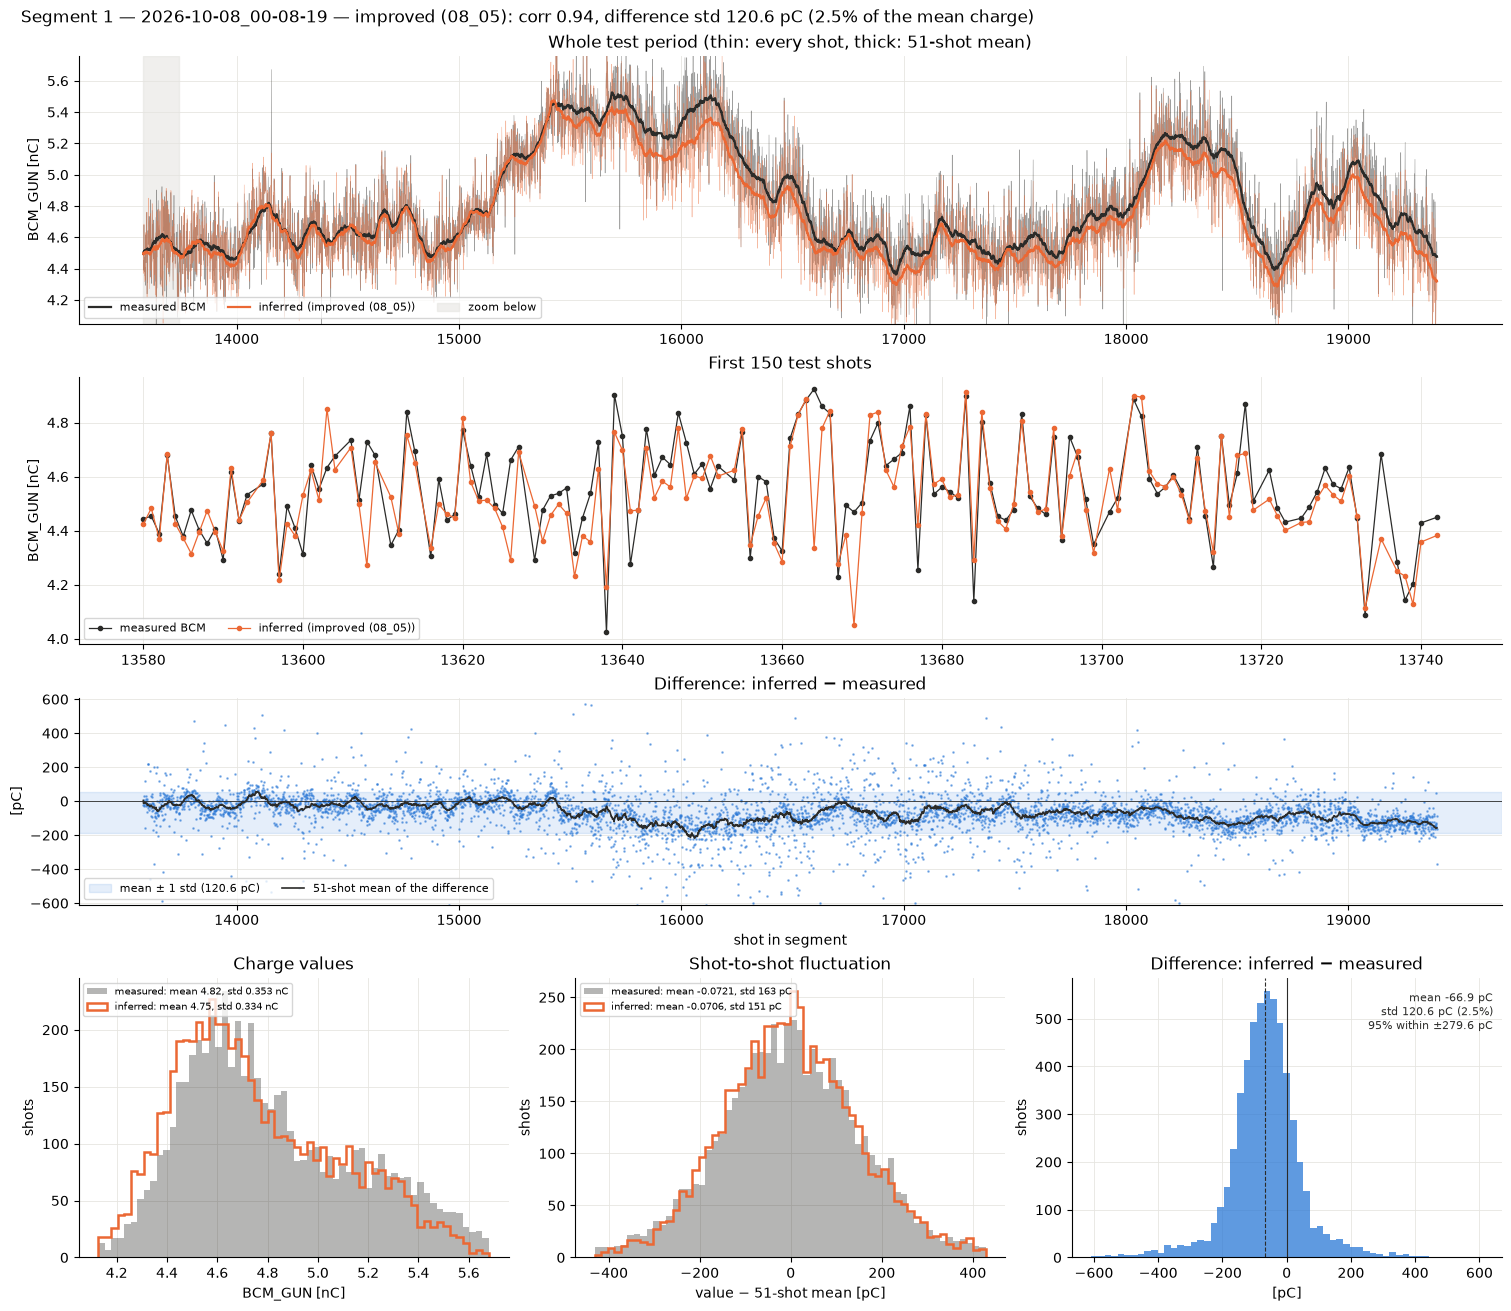

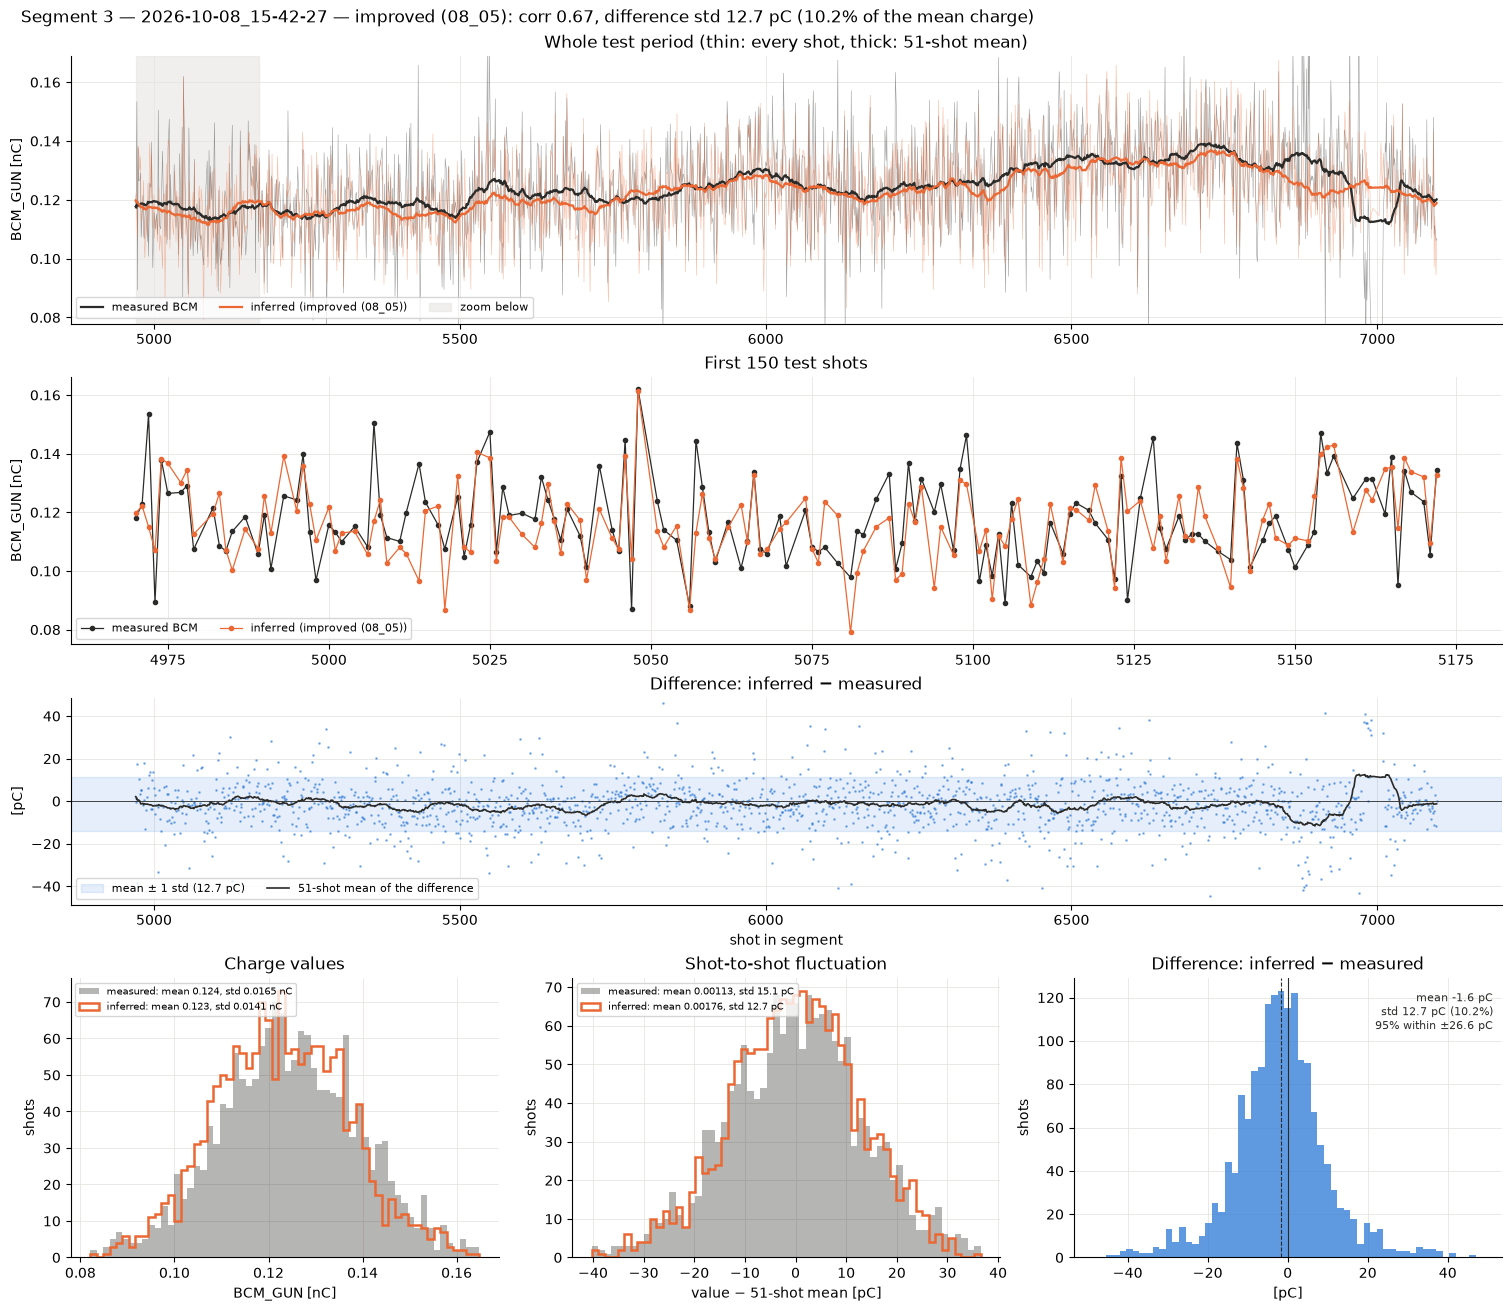

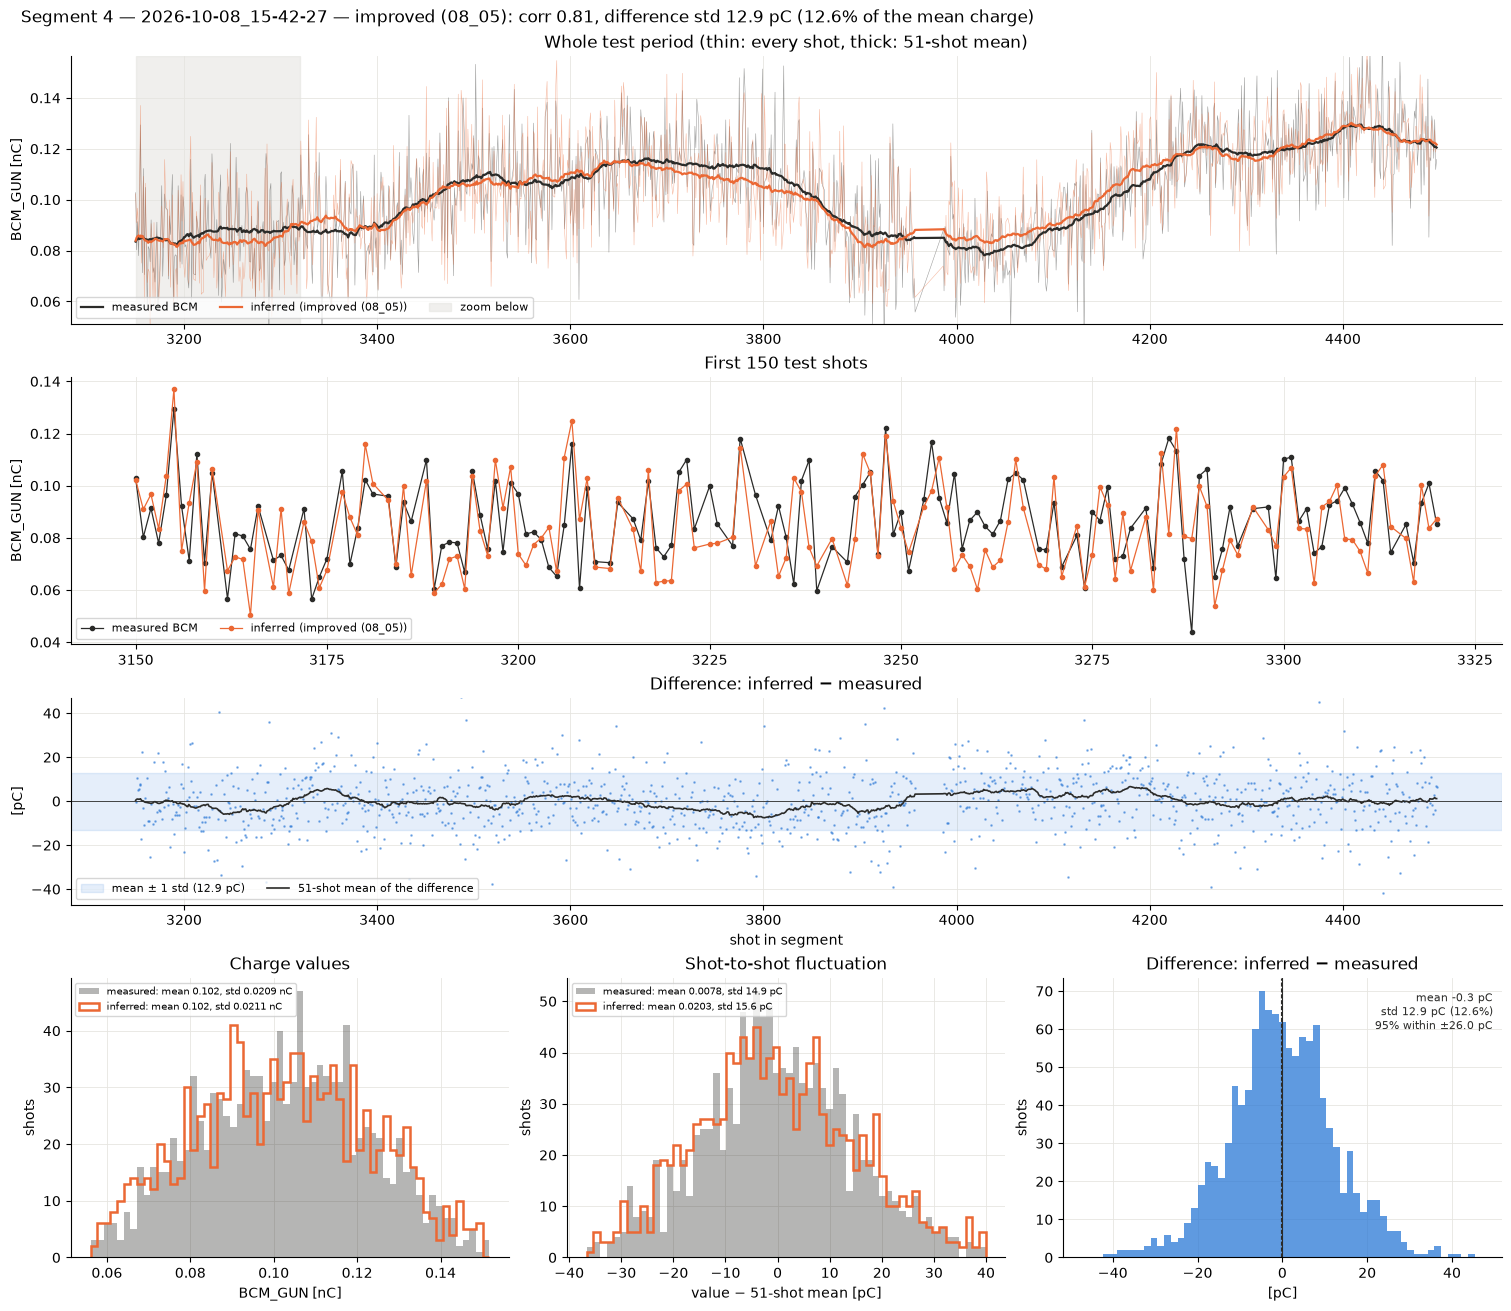

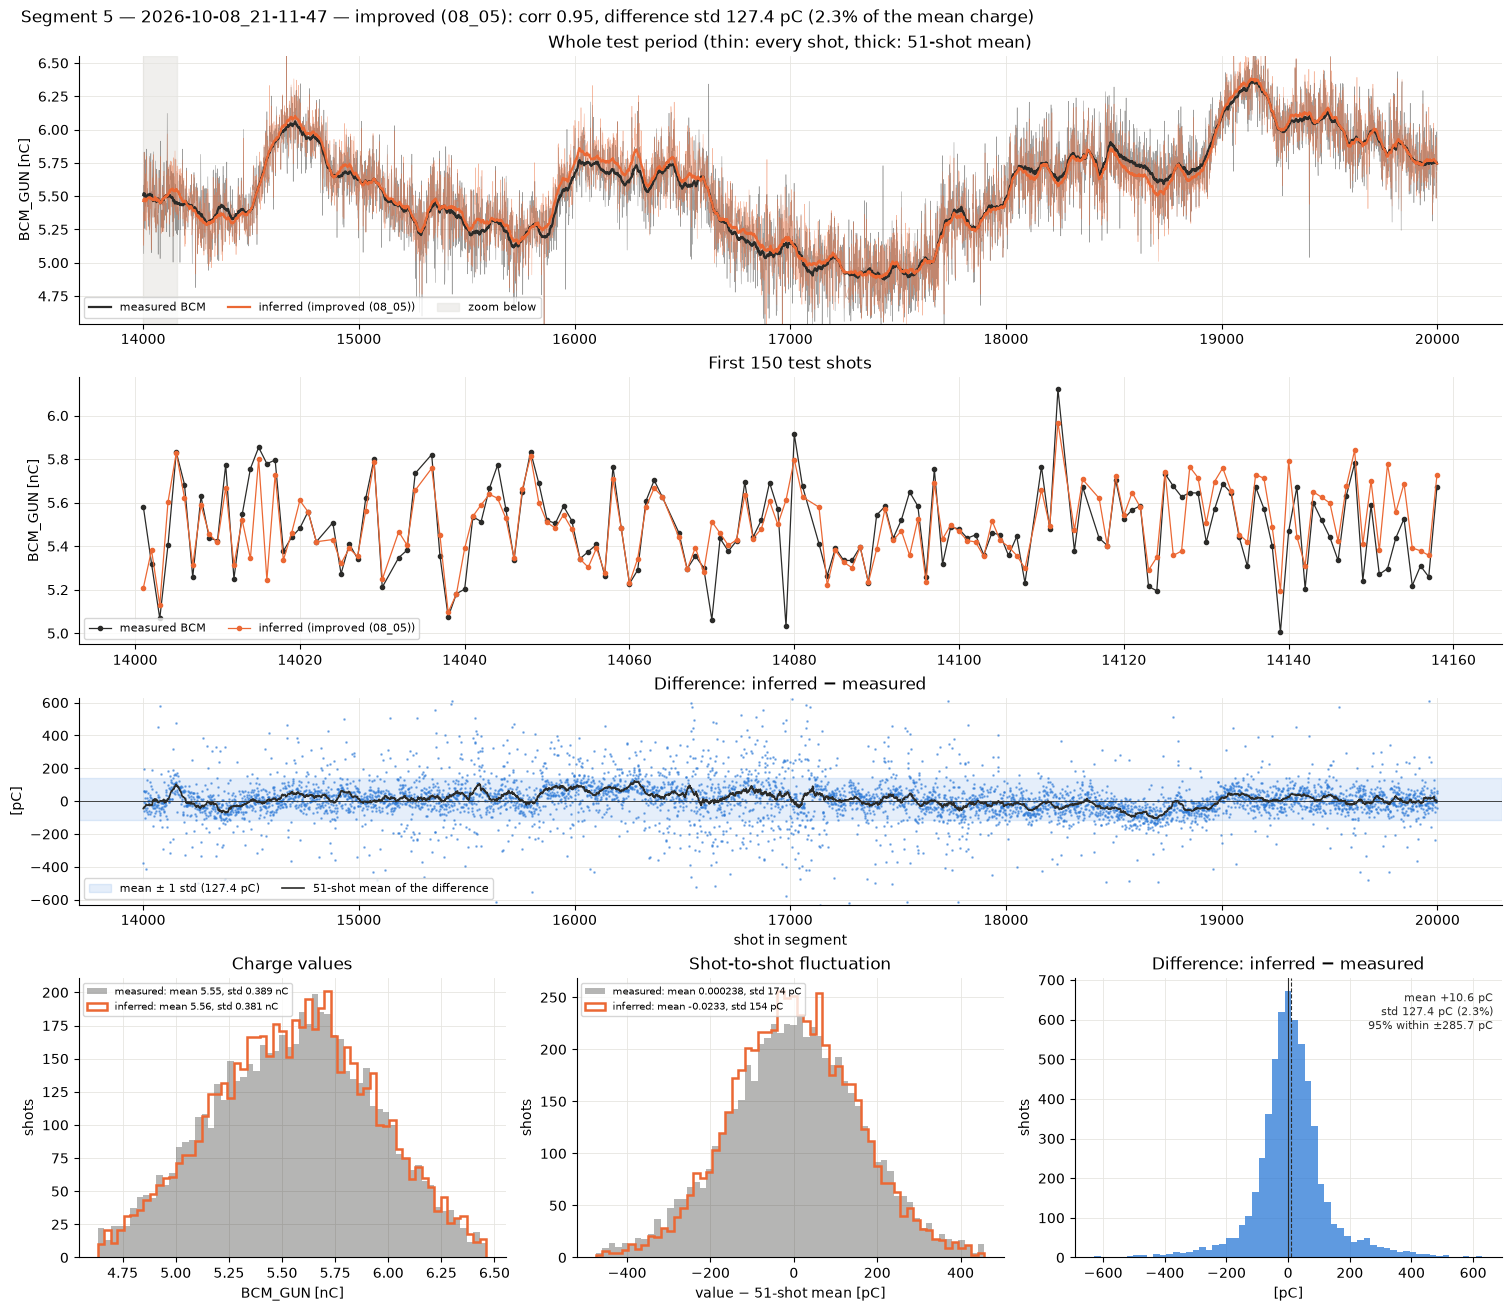

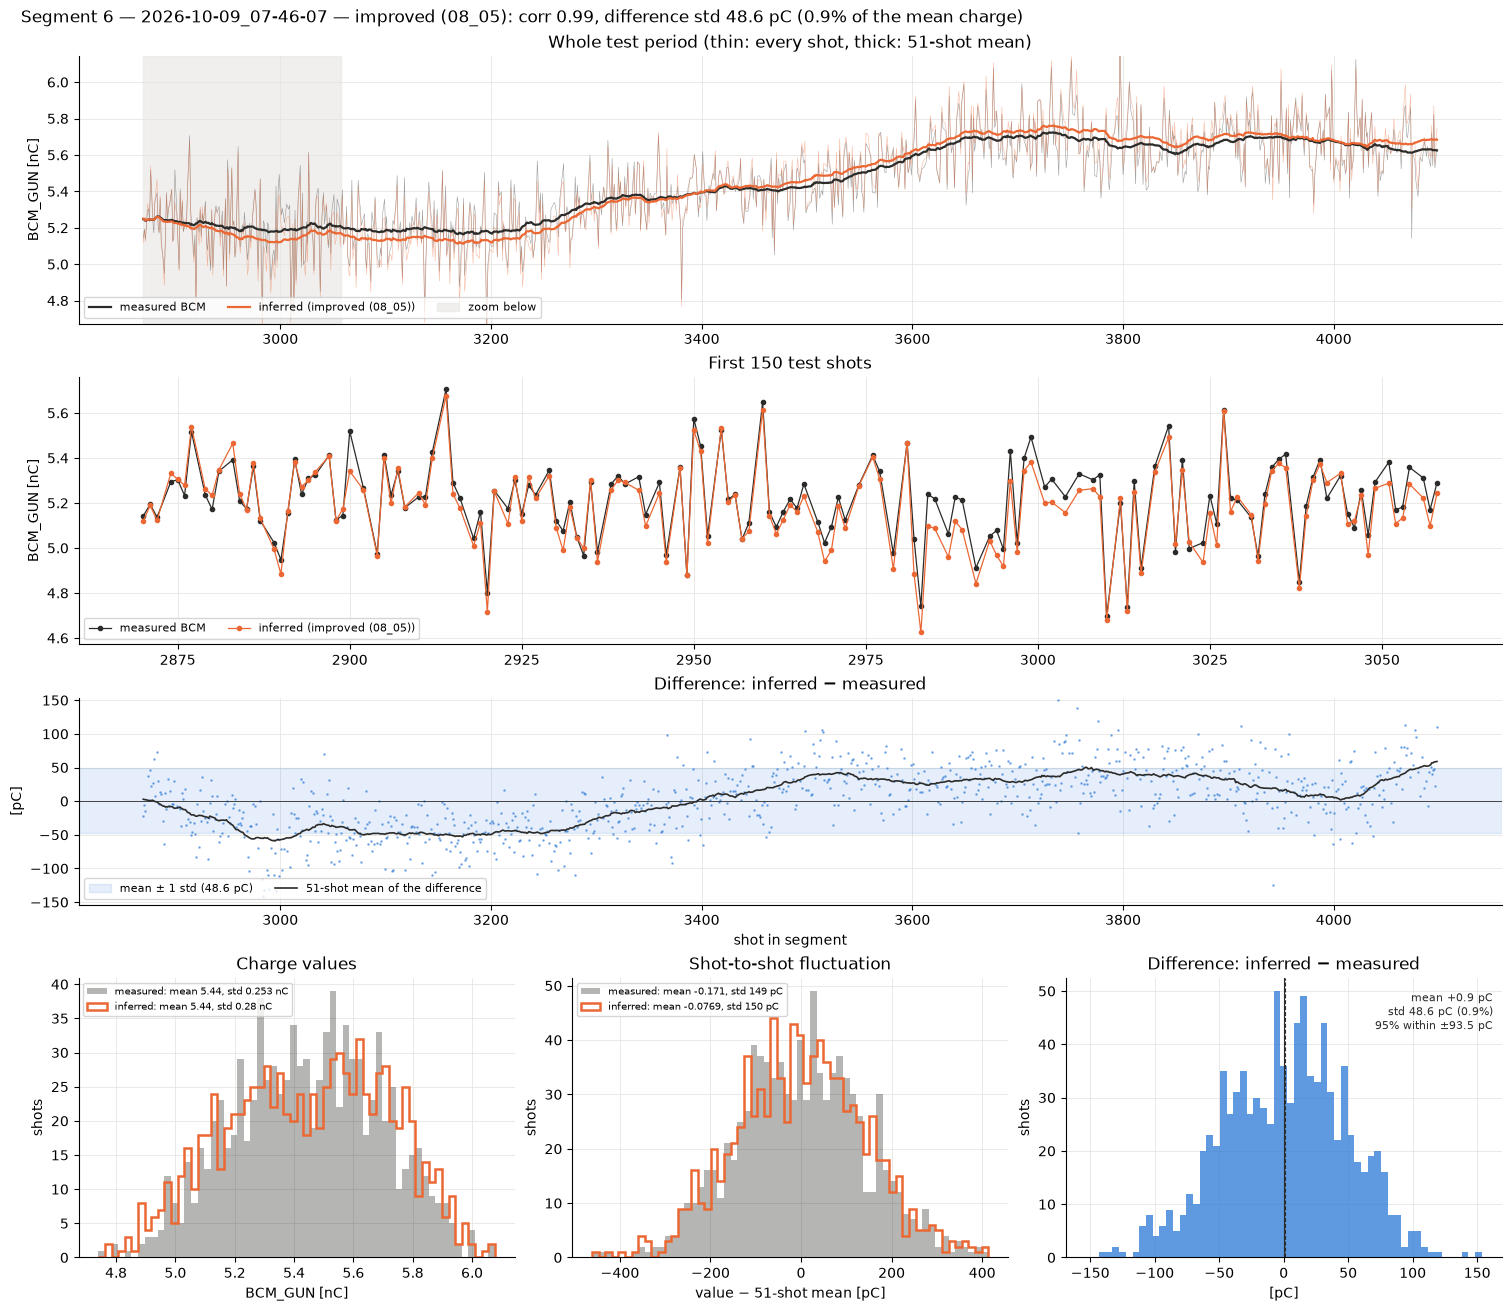

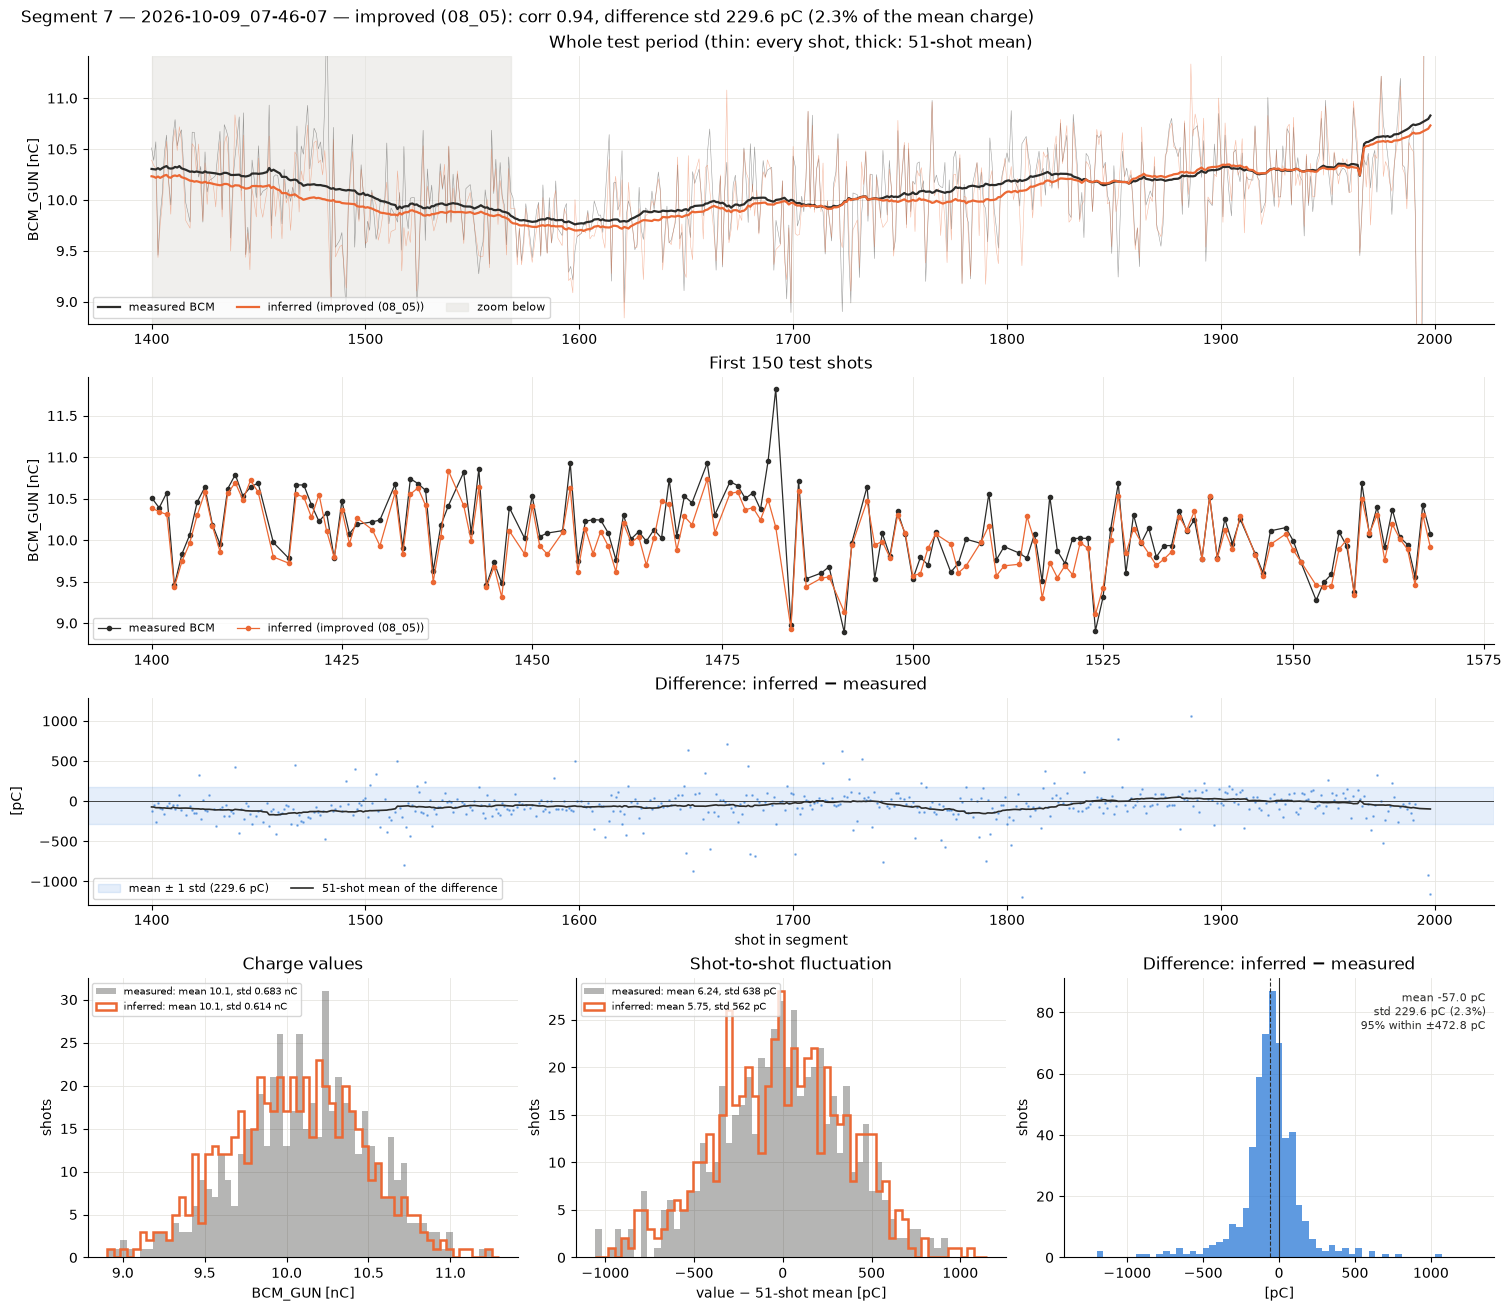

In [3]:
for k in segments:
    vd_plots.segment_figure(pred, k, MODEL, save_dir=FIGS)

## All segments: difference distributions (pC)

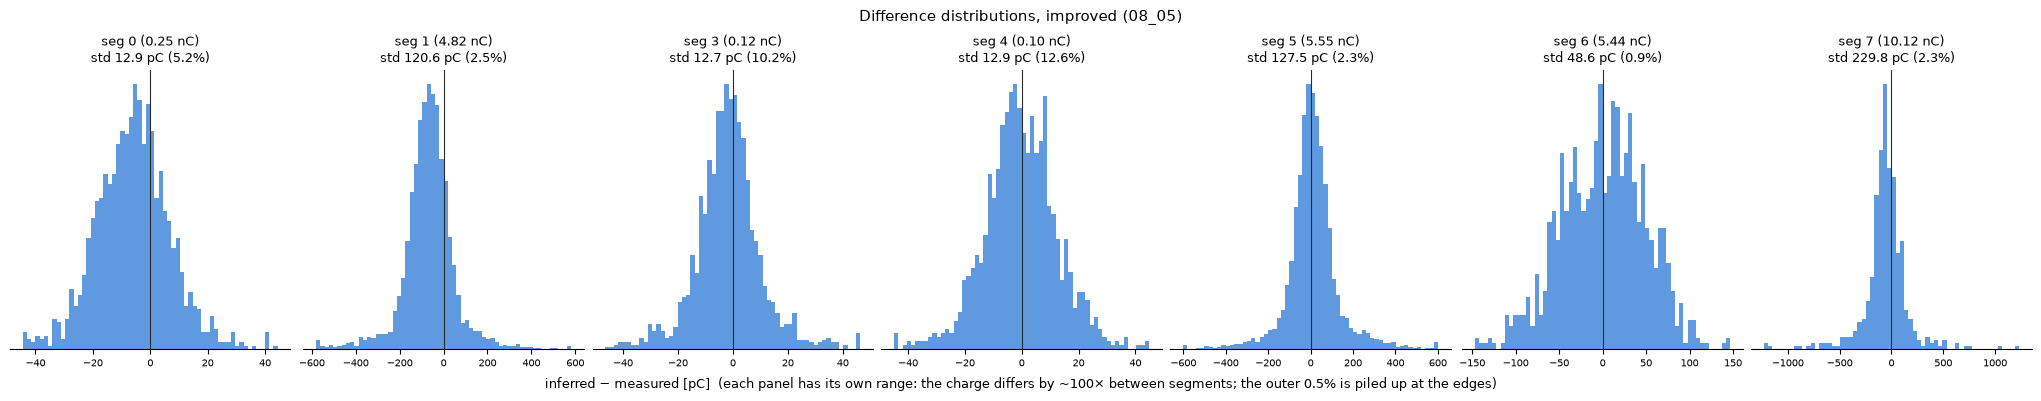

In [4]:
vd_plots.difference_all_segments(pred, MODEL, save_path=FIGS / "difference_all_segments.png")